# Delivery Time Prediction

Прогнозирование времени доставки заказов: анализ данных, сравнение моделей и оценка на отложенной части размеченного датасета.

## Цель проекта

Предсказать время доставки в днях (`delivery_time_days`) по параметрам заказа, склада, трафика и погоды. Целевая метрика — **MAE**: она показывает среднюю абсолютную ошибку прогноза в днях и менее чувствительна к единичным крупным ошибкам, чем MSE.

В проекте используется только размеченный `data/train.csv`; отложенная выборка выделяется из него локально.


## План эксперимента

1. До анализа разделить размеченные данные на обучающую и тестовую выборки.
2. На обучающей выборке проводить EDA и подбирать модели с помощью 5-fold кросс-валидации; по метрикам на валидационных фолдах выбирать эксперимент.
3. После выбора один раз оценить итоговую модель на тестовой выборке.

Тестовая выборка не используется для обучения и принятия решений по модели. `id` не является признаком модели.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = Path('data')
TARGET = 'delivery_time_days'
ID_COLUMN = 'id'

# Все метрики и признаки формируются из имеющегося размеченного train.csv.
df = pd.read_csv(DATA_DIR / 'train.csv')
assert TARGET in df.columns, f'В датасете отсутствует целевая колонка {TARGET!r}'
assert df[TARGET].notna().all(), 'В целевой колонке есть пропуски'

In [2]:
FEATURE_COLUMNS = [column for column in df.columns if column not in [TARGET, ID_COLUMN]]
X = df[FEATURE_COLUMNS].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
train_data = X_train.join(y_train.rename(TARGET))

print(f'Всего размеченных строк: {len(df)}')
print(f'Обучающая выборка: {len(X_train)}; тестовая выборка: {len(X_test)}')
print(f'Признаки модели ({len(FEATURE_COLUMNS)}): {FEATURE_COLUMNS}')

Всего размеченных строк: 4000
Обучающая выборка: 3200; тестовая выборка: 800
Признаки модели (6): ['distance_km', 'order_size', 'weight_kg', 'warehouse_load', 'traffic_index', 'weather_score']


## 1. Исследование обучающей выборки

Описательные статистики и графики строятся только по обучающей выборке. Тестовая выборка не участвует в исследовании и остаётся нетронутой до заключительной оценки.


In [3]:
train_data.describe().T

,count,mean,std,min,25%,50%,75%,max
distance_km,3200.0,278.039508,260.756786,0.067347,123.584003,257.603346,380.400810,2490.834790
order_size,3200.0,4.983125,1.776077,1.000000,4.000000,5.000000,6.000000,11.000000
weight_kg,3200.0,18.477022,23.084478,0.100000,11.435829,15.194213,19.052816,261.903519
warehouse_load,3200.0,0.492366,0.285755,0.000241,0.248691,0.485490,0.733501,0.999505
traffic_index,3200.0,4.013438,2.182114,0.000000,2.000000,4.000000,6.000000,10.000000
weather_score,3200.0,0.498573,0.220357,0.000000,0.349730,0.495794,0.651604,1.000000
delivery_time_days,3200.0,12.384767,6.942528,0.808371,7.301129,12.497794,15.452245,54.630762


In [4]:
train_data.isna().sum()

distance_km           0
order_size            0
weight_kg             0
warehouse_load        0
traffic_index         0
weather_score         0
delivery_time_days    0
dtype: int64

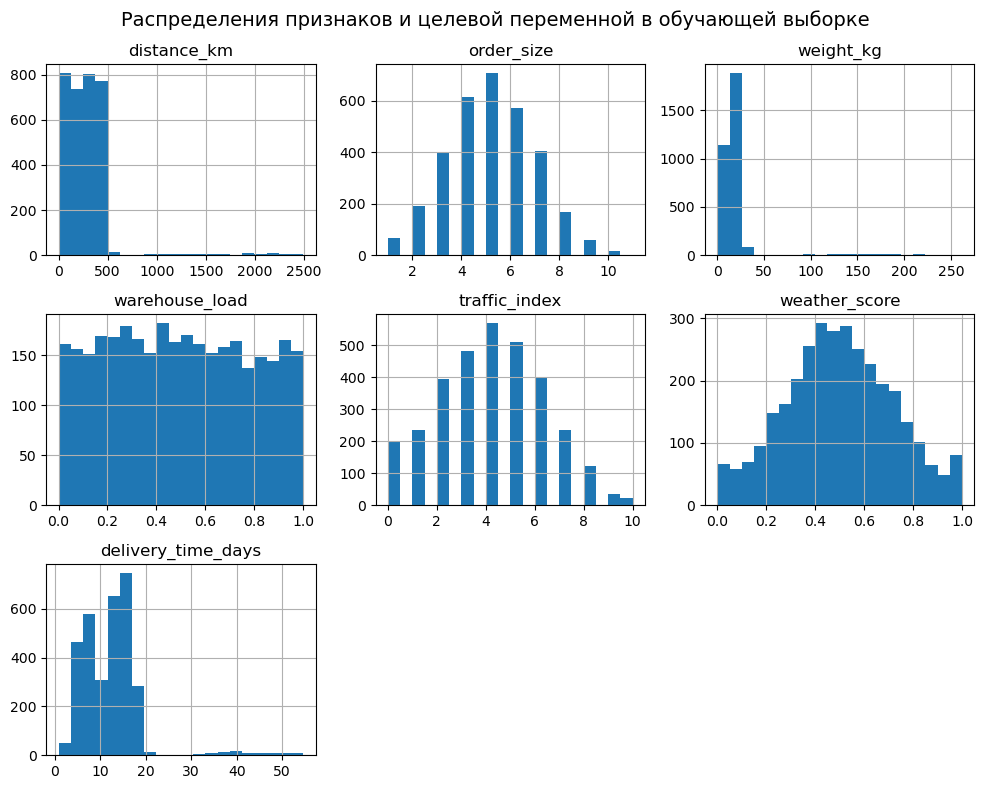

In [5]:
train_data.select_dtypes(include='number').hist(bins=20, figsize=(10, 8))
plt.suptitle('Распределения признаков и целевой переменной в обучающей выборке', fontsize=14)
plt.tight_layout()
plt.show()

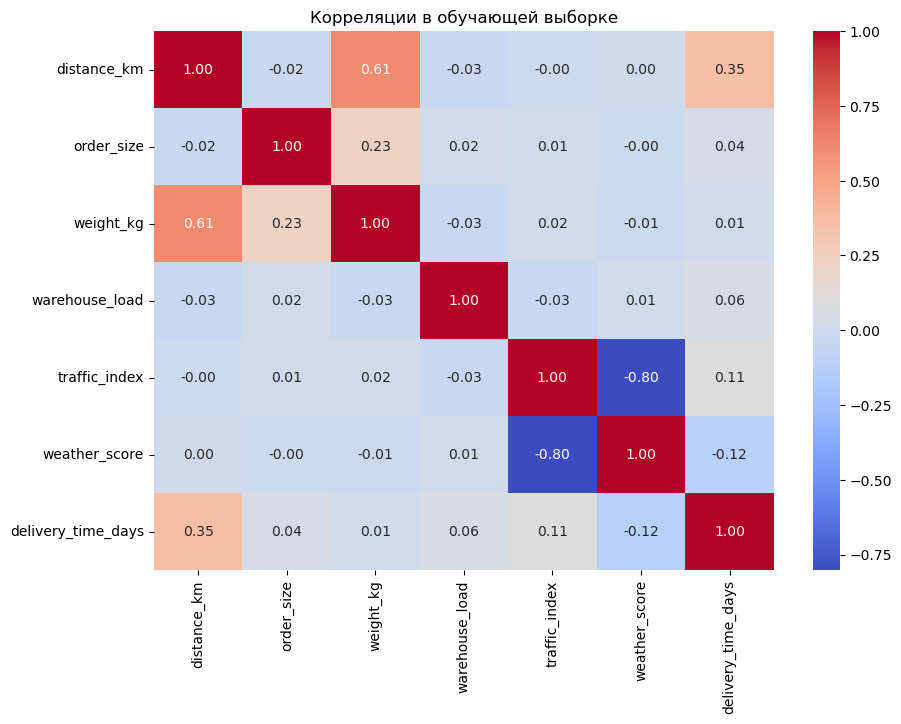

In [6]:
plt.figure(figsize=(10, 7))
sns.heatmap(train_data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляции в обучающей выборке')
plt.show()
plt.close()

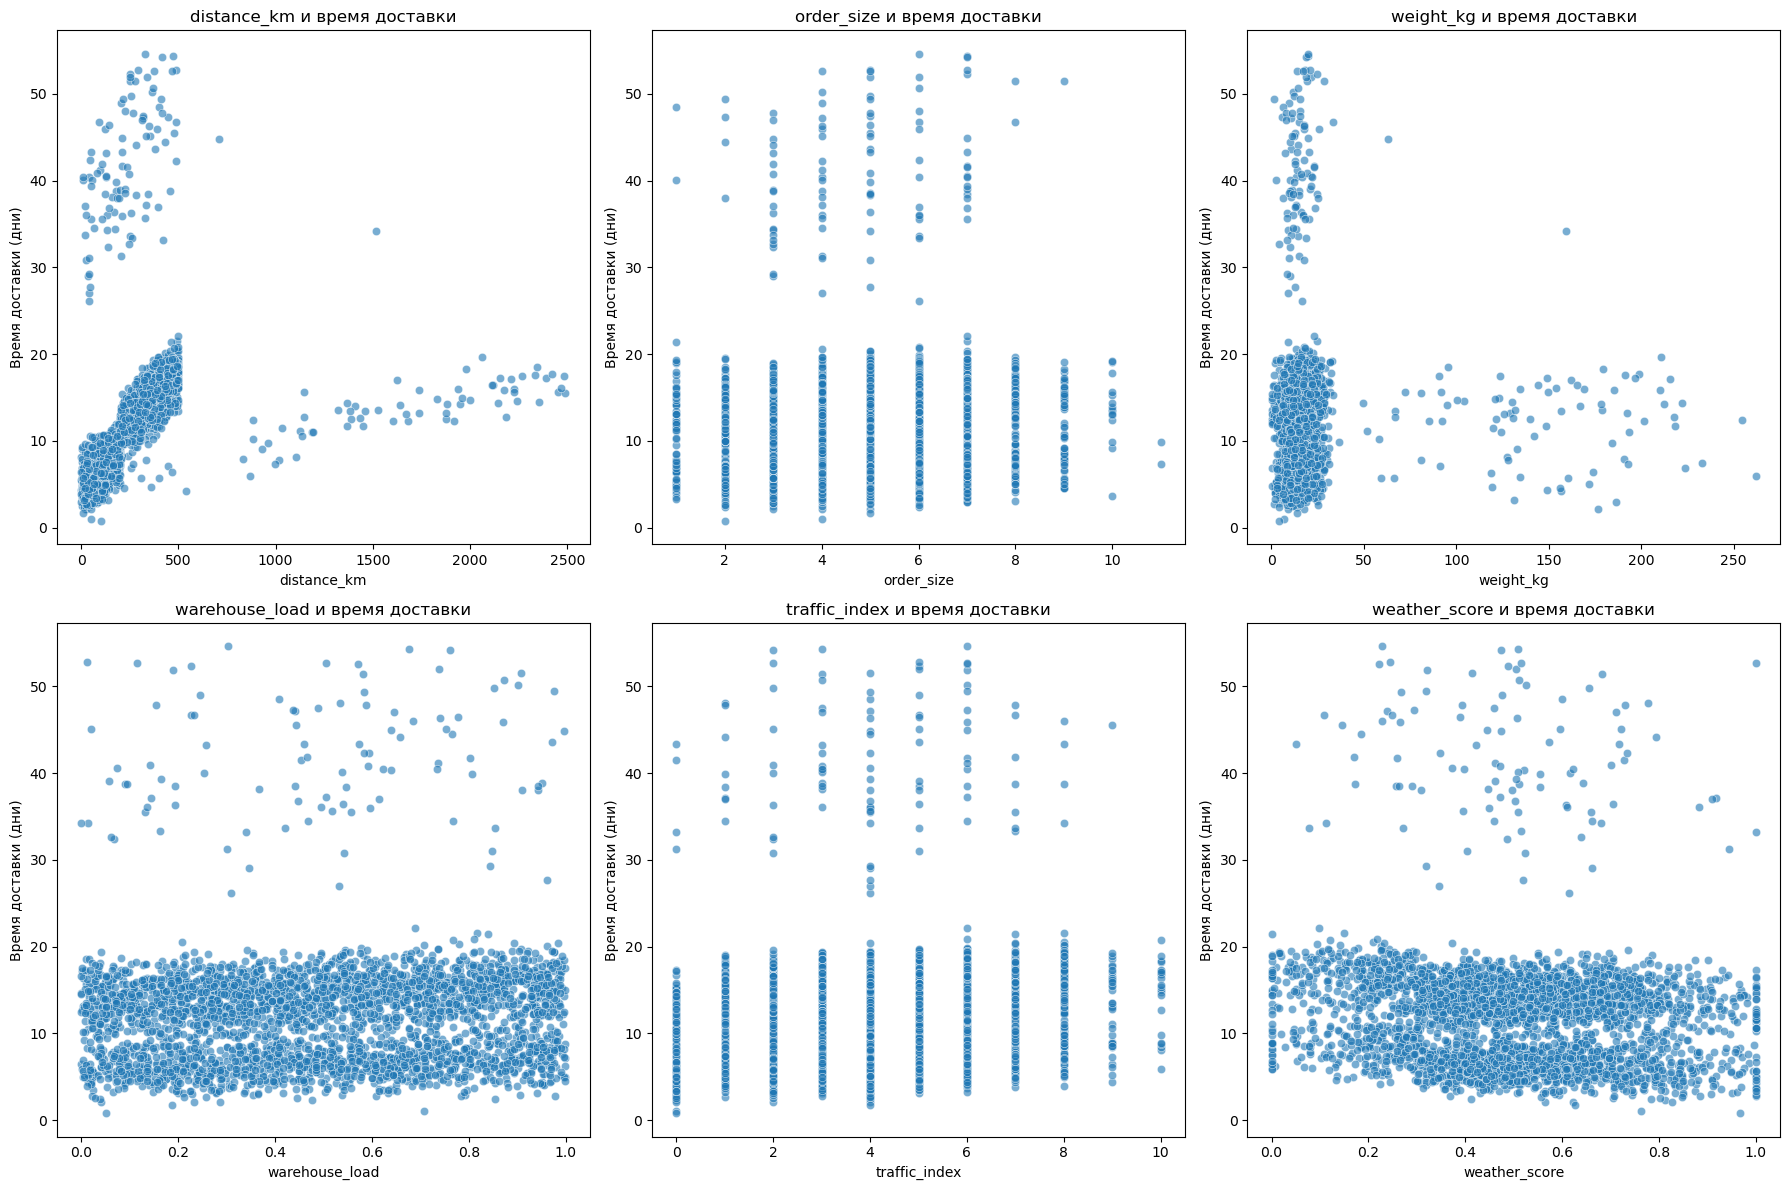

In [7]:
features = ['distance_km', 'order_size', 'weight_kg', 'warehouse_load', 'traffic_index', 'weather_score']
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, feature in zip(axes.flatten(), features):
    sns.scatterplot(x=train_data[feature], y=train_data[TARGET], ax=ax, alpha=0.6)
    ax.set_title(f'{feature} и время доставки')
    ax.set_xlabel(feature)
    ax.set_ylabel('Время доставки (дни)')
plt.tight_layout()
plt.show()

### Выводы по разведочному анализу

- В обучающей выборке 3 200 строк; пропусков в признаках и целевой переменной нет.
- Распределения расстояния, веса и времени доставки имеют длинный правый хвост: максимальные значения заметно выше 75-го перцентиля (например, `distance_km`: 2 490.8 км против Q3 = 380.4 км; `weight_kg`: 261.9 кг против Q3 = 19.1 кг; целевая переменная: 54.6 дня против Q3 = 15.5 дня).
- Самая заметная линейная связь с временем доставки у расстояния (`r = 0.353`). У остальных признаков корреляция слабее: погода `r = -0.123`, трафик `r = 0.106`; это не исключает нелинейных эффектов и взаимодействий.
- По отдельному правилу 1.5 IQR выбросами помечаются 65 значений расстояния (2.0%), 100 значений веса (3.1%) и 98 значений таргета (3.1%). Списки пересекаются; в итоге IQR-модель при refit на обучающей выборке использовала 3 005 из 3 200 строк.

**Решение для следующего шага:** не считать экстремальные значения ошибочными автоматически. Сравнить модель с фильтрацией и без неё по CV MAE, а затем один раз оценить выбранный вариант на отдельной тестовой выборке.


## 2. Базовая модель и подбор параметров

Подбор выполняется только на обучающей части. В качестве основной метрики и критерия выбора используется MAE.


In [8]:
param_distributions = {
    'max_depth': np.arange(1, 30),
    'min_samples_split': np.arange(2, 30),
    'min_samples_leaf': np.arange(1, 20),
}

def tune_tree(estimator, X_fit, y_fit, n_iter=100):
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring='neg_mean_absolute_error',
        cv=5,
        n_jobs=-1,
        random_state=42,
        refit=True,
    )
    search.fit(X_fit, y_fit)
    return search

baseline_search = tune_tree(DecisionTreeRegressor(random_state=42), X_train, y_train)
print('Параметры baseline:', baseline_search.best_params_)
print(f'CV MAE baseline: {-baseline_search.best_score_:.4f}')

Параметры baseline: {'min_samples_split': 19, 'min_samples_leaf': 19, 'max_depth': 3}
CV MAE baseline: 2.4170


## 3. Эксперимент: IQR-фильтрация

Границы IQR рассчитываются внутри `fit`. Поэтому в каждом CV-фолде они зависят только от его обучающей части, а валидационный фолд оценивается без фильтрации. Это предотвращает утечку статистик и выбор строк по целевой переменной из оцениваемого фолда.


In [9]:
class IQRFilteredTreeRegressor(RegressorMixin, BaseEstimator):
    def __init__(
        self,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        filter_features=('distance_km', 'weight_kg'),
        filter_target=True,
        iqr_multiplier=1.5,
        random_state=42,
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.filter_features = filter_features
        self.filter_target = filter_target
        self.iqr_multiplier = iqr_multiplier
        self.random_state = random_state

    def fit(self, X, y):
        X = pd.DataFrame(X).copy()
        y = np.asarray(y, dtype=float)
        if len(X) != len(y):
            raise ValueError('X and y must contain the same number of rows')

        keep = np.isfinite(y)
        for feature in self.filter_features:
            if feature not in X.columns:
                raise ValueError(f'Missing filtering feature: {feature}')
            values = X[feature].to_numpy(dtype=float)
            finite = np.isfinite(values)
            keep &= finite
            q1, q3 = np.quantile(values[finite], [0.25, 0.75])
            iqr = q3 - q1
            keep &= (values >= q1 - self.iqr_multiplier * iqr)
            keep &= (values <= q3 + self.iqr_multiplier * iqr)

        if self.filter_target:
            finite_y = np.isfinite(y)
            q1, q3 = np.quantile(y[finite_y], [0.25, 0.75])
            iqr = q3 - q1
            keep &= (y >= q1 - self.iqr_multiplier * iqr)
            keep &= (y <= q3 + self.iqr_multiplier * iqr)

        if keep.sum() < 2:
            raise ValueError('IQR filtering left fewer than two training rows')

        self.n_training_samples_ = int(keep.sum())
        self.tree_ = DecisionTreeRegressor(
            max_depth=self.max_depth,
            min_samples_split=self.min_samples_split,
            min_samples_leaf=self.min_samples_leaf,
            random_state=self.random_state,
        )
        self.tree_.fit(X.loc[keep], y[keep])
        return self

    def predict(self, X):
        return self.tree_.predict(X)


# Для IQR-модели проверяем те же наборы гиперпараметров и те же CV-folds.
iqr_search = tune_tree(IQRFilteredTreeRegressor(), X_train, y_train, n_iter=200)
print('Параметры IQR-модели:', iqr_search.best_params_)
print(f'CV MAE IQR: {-iqr_search.best_score_:.4f}')
print(f'Строк в refit-модели: {iqr_search.best_estimator_.n_training_samples_}/{len(X_train)}')

Параметры IQR-модели: {'min_samples_split': 7, 'min_samples_leaf': 17, 'max_depth': 11}
CV MAE IQR: 1.9407
Строк в refit-модели: 3005/3200


## 4. Эксперимент: дополнительный признак

Проверяем отношение расстояния к весу. Преобразование детерминированное и не оценивает параметры по данным, поэтому одинаково применяется к обучающей и тестовой выборкам.


In [10]:
def add_ratio(data):
    result = data.copy()
    denominator = result['weight_kg'].replace(0, np.nan)
    ratio = result['distance_km'] / denominator
    result['distance_to_weight_ratio'] = ratio.replace([np.inf, -np.inf], np.nan).fillna(0)
    return result

X_train_fe = add_ratio(X_train)
X_test_fe = add_ratio(X_test)

feature_search = tune_tree(IQRFilteredTreeRegressor(), X_train_fe, y_train, n_iter=200)
print('Параметры IQR + ratio:', feature_search.best_params_)
print(f'CV MAE IQR + ratio: {-feature_search.best_score_:.4f}')

Параметры IQR + ratio: {'min_samples_split': 18, 'min_samples_leaf': 17, 'max_depth': 13}
CV MAE IQR + ratio: 1.9446


## 5. Выбор и финальная оценка

Вариант выбирается по среднему CV MAE на обучающей выборке. Внутренние валидационные фолды участвуют в выборе модели, но не используются для её подгонки в соответствующем фолде. Только после выбора оцениваем модель на тестовой выборке, которая не участвовала в EDA, подборе параметров или выборе эксперимента.


In [11]:
cv_results = pd.DataFrame([
    {'experiment': 'Decision tree baseline', 'CV MAE': -baseline_search.best_score_},
    {'experiment': 'IQR-filtered tree', 'CV MAE': -iqr_search.best_score_},
    {'experiment': 'IQR + distance/weight ratio', 'CV MAE': -feature_search.best_score_},
]).sort_values('CV MAE').reset_index(drop=True)
cv_results

,experiment,CV MAE
0,IQR-filtered tree,1.940731
1,IQR + distance/weight ratio,1.944624
2,Decision tree baseline,2.416972


### Выводы по кросс-валидации

IQR-фильтр дал наименьшую среднюю CV MAE: **1.9407 дня** против **2.4170 дня** у обычного дерева (снижение примерно на 19.7%). Добавление отношения расстояния к весу не улучшило результат: CV MAE **1.9446 дня**, немного выше варианта только с IQR-фильтром. Поэтому по заранее выбранному критерию для финальной проверки выбирается IQR-модель без нового признака.

Разница между IQR-моделью и вариантом с новым признаком мала (**0.0039 дня**), поэтому не следует трактовать её как сильный или устойчивый эффект. Окончательная независимая оценка будет показана ниже на тестовой выборке.


In [12]:
searches = {
    'Decision tree baseline': baseline_search,
    'IQR-filtered tree': iqr_search,
    'IQR + distance/weight ratio': feature_search,
}
selected_experiment = cv_results.loc[0, 'experiment']
final_model = searches[selected_experiment].best_estimator_

# Модель выбираем по CV; тестовая выборка используется только для итогового сравнения.
baseline_model = baseline_search.best_estimator_
y_pred_baseline_test = baseline_model.predict(X_test)
y_pred_test = final_model.predict(X_test_fe if selected_experiment == 'IQR + distance/weight ratio' else X_test)
median_baseline = DummyRegressor(strategy='median').fit(X_train, y_train)
y_pred_median = median_baseline.predict(X_test)

final_results = pd.DataFrame([
    {
        'model': 'Median baseline',
        'MAE': mean_absolute_error(y_test, y_pred_median),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_median)),
        'R2': r2_score(y_test, y_pred_median),
    },
    {
        'model': 'Decision tree baseline (selected by CV)',
        'MAE': mean_absolute_error(y_test, y_pred_baseline_test),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_baseline_test)),
        'R2': r2_score(y_test, y_pred_baseline_test),
    },
    {
        'model': f'Selected: {selected_experiment}',
        'MAE': mean_absolute_error(y_test, y_pred_test),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_test)),
        'R2': r2_score(y_test, y_pred_test),
    },
])
print(f'Выбранная по CV модель: {selected_experiment}')
print(f'Обучено строк: {len(X_train)}; независимая тестовая выборка: {len(X_test)}')
final_results

Выбранная по CV модель: IQR-filtered tree
Обучено строк: 3200; независимая тестовая выборка: 800


,model,MAE,RMSE,R2
0,Median baseline,4.461255,6.260801,-0.003520
1,Decision tree baseline (selected by CV),2.103482,4.495600,0.482582
2,Selected: IQR-filtered tree,1.635380,4.419324,0.499991


## Итоговые выводы и ограничения

- По средней MAE в 5-fold кросс-валидации выбрана модель дерева решений с IQR-фильтрацией обучающих строк (**1.9407 дня**). Добавленный признак `distance_to_weight_ratio` заметного улучшения не показал (**1.9446 дня**), поэтому в выбранную модель не включён.
- На нетронутой тестовой выборке из 800 строк MAE выбранной модели — **1.6354 дня**, RMSE — **4.4193 дня**, R² — **0.5000**. Для сравнения, настроенное обычное дерево получило MAE **2.1035 дня**, а предсказание медианой — **4.4613 дня**. Таким образом, на данном разбиении IQR-модель снизила MAE примерно на **22.3%** относительно обычного дерева.
- RMSE заметно выше MAE, что указывает на наличие отдельных больших ошибок: квадрат ошибки сильнее учитывает такие случаи. Поэтому одной средней MAE недостаточно для оценки риска крупных промахов; при дальнейшем развитии проекта стоит отдельно исследовать ошибки по диапазонам времени доставки и признакам.
- IQR-фильтрация улучшила метрику в этом эксперименте, но удалённые наблюдения не обязательно являются ошибками — это могут быть редкие, но реальные заказы. В реальном применении нужно проверить, не ухудшается ли качество именно на таких случаях.

Тестовая выборка использована только для итоговой оценки, а не для выбора модели. Результат относится к одному фиксированному разбиению 4 000 строк и не гарантирует такое же качество на новых периодах, регионах или типах заказов. Для оценки устойчивости полезны повторные разбиения или временная валидация на новых данных.
